In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os, sys, json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/simuteh-2330511091"
os.chdir(os.path.join(BASE, "notebook"))
sys.path.insert(0, os.path.join(BASE, "src"))

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import (
    tepi_acuan, skor_tepi, iou,
    mask_daun_awal, bercak_awal
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

PARAM = json.load(open(os.path.join(BASE, "hasil", "param_praproses.json")))
label = pd.read_csv(os.path.join(BASE, "data", "sintetis", "label.csv"))

def muat(nama):
    img = baca(os.path.join(BASE, "data", "sintetis", "citra", nama))
    md = cv2.imread(os.path.join(BASE, "data", "sintetis", "mask_daun", nama), 0)
    mb = cv2.imread(os.path.join(BASE, "data", "sintetis", "mask_bercak", nama), 0)
    return img, md, mb

# Fungsi Canny dari praktikum sebelumnya
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

print("Persiapan P6 berhasil.")
print("Jumlah data:", len(label))


Persiapan P6 berhasil.
Jumlah data: 60


         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.995                   246               9           0.524
1  teh_021.png          0.997                   206               1            0.03
2  teh_011.png          0.998                   221               0               -


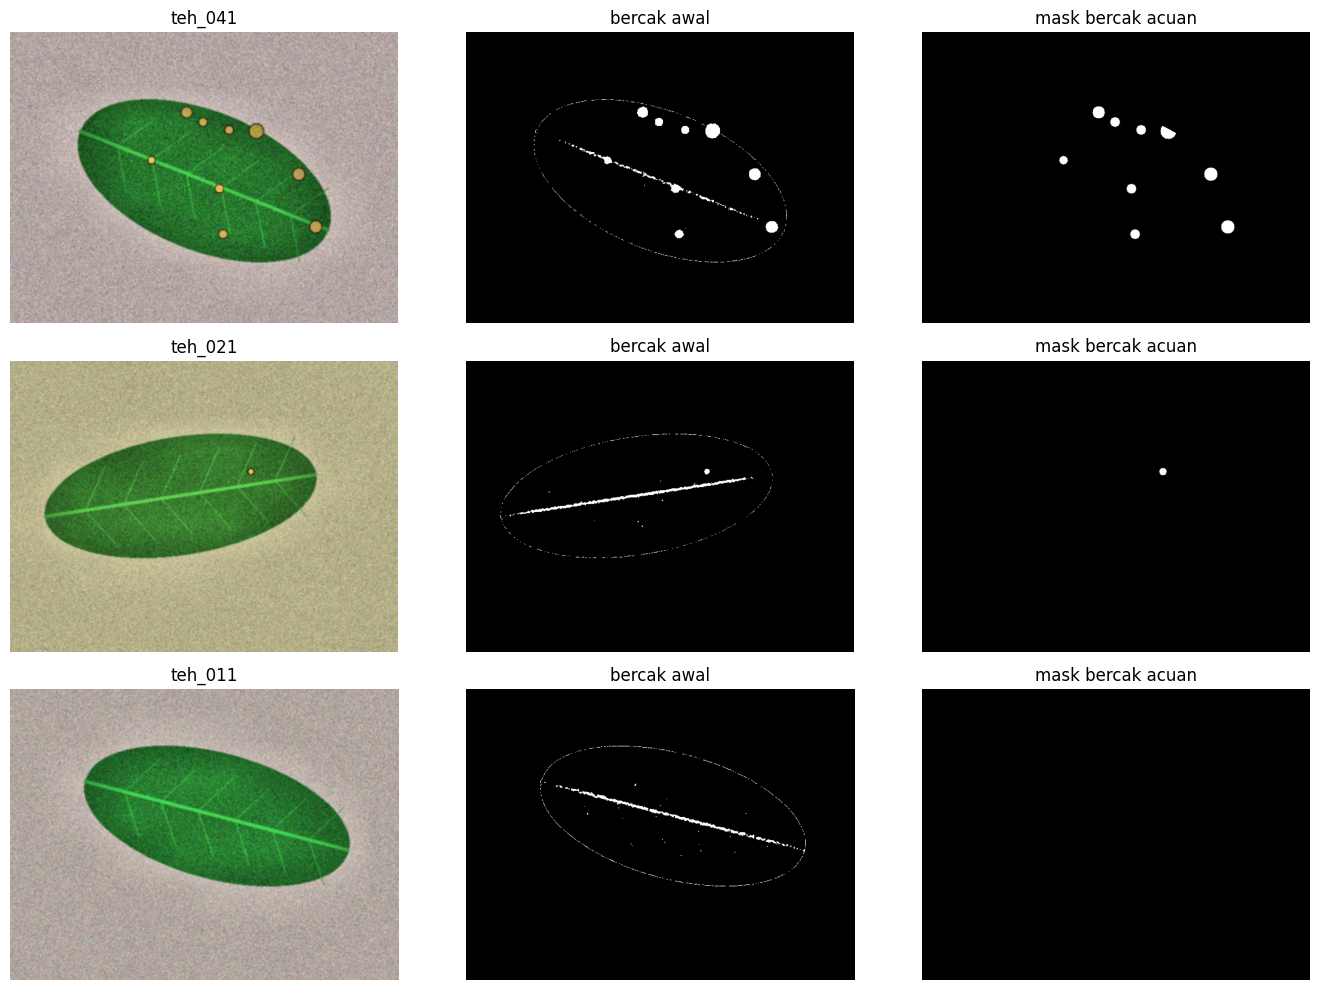

In [ ]:

def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )[0] - 1

baris, panel, judul = [], [], []

for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)

    pra_ = praproses(img, PARAM)

    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)

    baris.append([
        nama,
        round(iou(m_daun, md), 3),
        jumlah_komponen(b0),
        jumlah_komponen(mb),
        round(iou(b0, mb), 3) if mb.any() else "-"
    ])

    panel += [pra_, b0, mb]
    judul += [nama[:7], "bercak awal", "mask bercak acuan"]

tabel = pd.DataFrame(
    baris,
    columns=[
        "citra",
        "IoU daun awal",
        "komponen bercak awal",
        "komponen acuan",
        "IoU bercak awal"
    ]
)

print(tabel)

tampil(panel, judul, baris=3, ukuran=(14, 10))


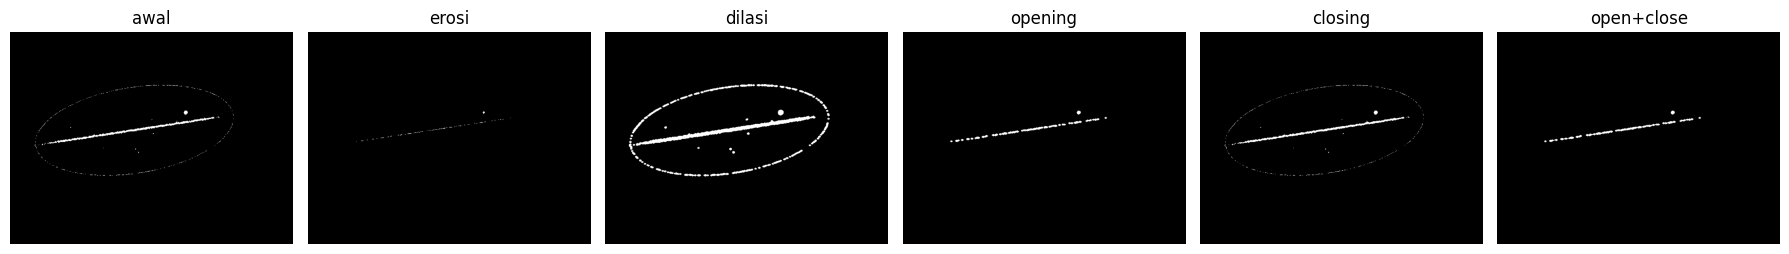

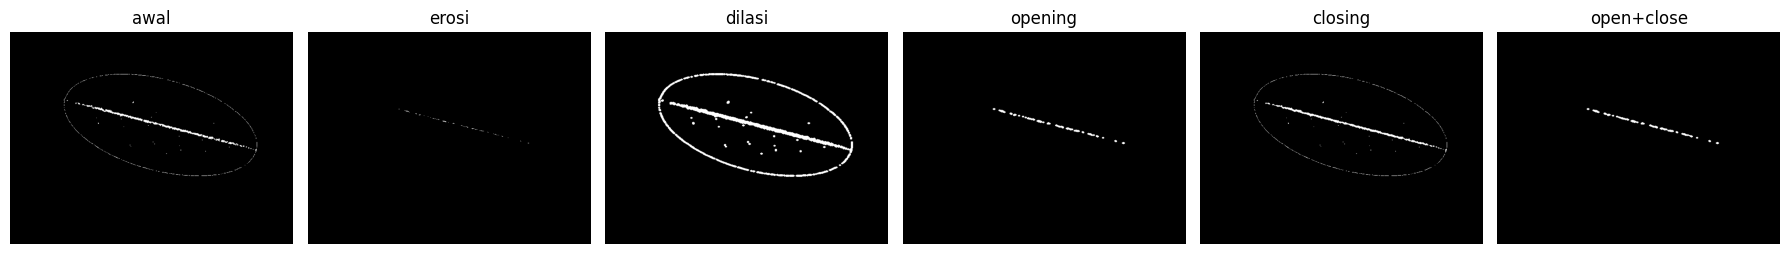

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       206    2103   0.03
1   teh_021.png       erosi        56     161  0.066
2   teh_021.png      dilasi        56    7335  0.015
3   teh_021.png     opening        21    1200  0.048
4   teh_021.png     closing       202    2152  0.029
5   teh_021.png  open+close        10    1237  0.047
6   teh_011.png        awal       221    2175      -
7   teh_011.png       erosi        40     105      -
8   teh_011.png      dilasi        33    8388      -
9   teh_011.png     opening        18     819      -
10  teh_011.png     closing       207    2331      -
11  teh_011.png  open+close        15     847      -


In [ ]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k,
k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN,
se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3));
plt.show()
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel",
"IoU"]))

In [ ]:

# LANGKAH 3.4 - EKSPERIMEN AMBANG DAN STRUCTURING ELEMENT

# Variasi bentuk Structuring Element
bentuk = {
    "persegi": cv2.MORPH_RECT,
    "elips": cv2.MORPH_ELLIPSE,
    "silang": cv2.MORPH_CROSS
}

# Fungsi pembentuk SE
def SE(k, bentuk_se=cv2.MORPH_ELLIPSE):
    return cv2.getStructuringElement(bentuk_se, (k, k))

baris = []

# Pengujian seluruh 60 citra
for _, d in label.iterrows():

    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)

    # Mask daun dan jumlah komponen acuan
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)

    # Variasi nilai k
    for k in [3, 4, 6]:

        b0 = bercak_awal(pra_, m_daun, k=k)

        # Variasi bentuk SE
        for nb, kb in bentuk.items():

            # Variasi ukuran SE
            for uk in [3, 5, 7]:

                se = SE(uk, kb)

                # Opening dilanjutkan closing
                m = cv2.morphologyEx(
                    cv2.morphologyEx(b0, cv2.MORPH_OPEN, se),
                    cv2.MORPH_CLOSE,
                    se
                )

                # Hitung galat jumlah komponen dan IoU
                galat = abs(jumlah_komponen(m) - n_acuan)

                nilai_iou = iou(m, mb) if mb.any() else np.nan

                baris.append([
                    d.kelas,
                    k,
                    nb,
                    uk,
                    galat,
                    nilai_iou
                ])

# Membuat DataFrame hasil eksperimen
eks = pd.DataFrame(
    baris,
    columns=[
        "kelas",
        "k",
        "bentuk",
        "ukuran",
        "galat_jumlah",
        "IoU"
    ]
)

# Menampilkan ringkasan hasil
print("JUMLAH DATA EKSPERIMEN:", len(eks))
print("\nRINGKASAN HASIL EKSPERIMEN SE")

print(
    eks.pivot_table(
        index=["k", "bentuk", "ukuran"],
        columns="kelas",
        values=["galat_jumlah", "IoU"]
    ).round(3)
)

# Menyimpan hasil eksperimen
os.makedirs(os.path.join(BASE, "hasil"), exist_ok=True)

eks.to_csv(
    os.path.join(BASE, "hasil", "p6_eksperimen_se.csv"),
    index=False
)

print("\nHasil tersimpan di hasil/p6_eksperimen_se.csv")


JUMLAH DATA EKSPERIMEN: 1620

RINGKASAN HASIL EKSPERIMEN SE
                    IoU        galat_jumlah              
kelas             berat ringan        berat ringan  sehat
k bentuk  ukuran                                         
3 elips   3       0.611  0.206        11.20  36.05  16.75
          5       0.655  0.311         3.95   2.00   6.05
          7       0.709  0.447         1.15   2.35   1.00
  persegi 3       0.618  0.247         6.65   8.70   8.20
          5       0.687  0.340         2.75   3.35   4.55
          7       0.686  0.455         0.90   0.85   0.10
  silang  3       0.611  0.206        11.20  36.05  16.75
          5       0.656  0.300         7.60   4.55   9.45
          7       0.711  0.433         2.35   3.50   3.00
4 elips   3       0.668  0.300        10.00  13.75  17.10
          5       0.690  0.373         1.70   3.45   3.10
          7       0.680  0.493         1.00   0.70   0.00
  persegi 3       0.674  0.333         6.10   4.65  10.15
          5 

In [ ]:

# LANGKAH 3.5 - GRADIEN MORFOLOGI VS CANNY

baris = []

for _, d in label.iterrows():

    img, md, mb = muat(d.nama_file)

    # Praproses citra
    pra_ = praproses(img, PARAM)

    # Membuat mask daun awal
    m_daun = mask_daun_awal(pra_)

    # Gradien morfologi (dilasi - erosi)
    grad = cv2.morphologyEx(
        m_daun,
        cv2.MORPH_GRADIENT,
        SE(3)
    )

    # Deteksi tepi menggunakan Canny
    gray = cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)
    canny = tepi_canny(gray)

    # Tepi acuan dari mask daun
    ad = tepi_acuan(md)

    # Menghitung F1 masing-masing metode
    f1_grad = skor_tepi(grad, ad)[2]
    f1_canny = skor_tepi(canny, ad)[2]

    baris.append([
        d.kondisi_cahaya,
        f1_grad,
        f1_canny
    ])

# Membuat tabel hasil
hasil_35 = pd.DataFrame(
    baris,
    columns=[
        "kondisi",
        "F1 gradien morfologi",
        "F1 Canny"
    ]
)

ringkasan_35 = hasil_35.groupby("kondisi").mean().round(3)

print("HASIL PERBANDINGAN GRADIEN MORFOLOGI DAN CANNY")
print(ringkasan_35)


HASIL PERBANDINGAN GRADIEN MORFOLOGI DAN CANNY
                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.869     0.718
gelap                          0.983     0.690
kontras_rendah                 0.122     0.894
normal                         0.984     0.690
terang                         0.897     0.694


In [ ]:
hasil_35.to_csv(
    os.path.join(BASE, "hasil", "p6_gradien_vs_canny.csv"),
    index=False
)

print("Hasil tersimpan di hasil/p6_gradien_vs_canny.csv")

Hasil tersimpan di hasil/p6_gradien_vs_canny.csv


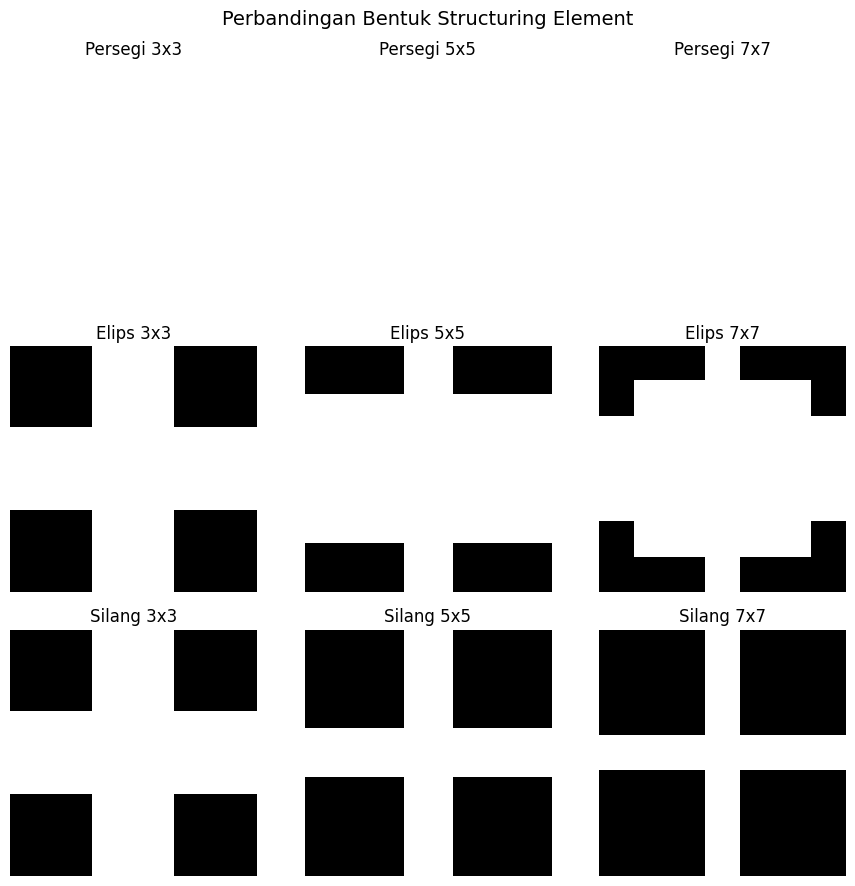

In [ ]:
# LANGKAH 3.6 - VISUALISASI BENTUK STRUCTURING ELEMENT

bentuk = {
    "Persegi": cv2.MORPH_RECT,
    "Elips": cv2.MORPH_ELLIPSE,
    "Silang": cv2.MORPH_CROSS
}

ukuran = [3, 5, 7]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, (nama, kode_bentuk) in enumerate(bentuk.items()):
    for j, k in enumerate(ukuran):
        se = cv2.getStructuringElement(
            kode_bentuk, (k, k)
        )

        axes[i, j].imshow(
            se, cmap="gray", vmin=0, vmax=1
        )
        axes[i, j].set_title(f"{nama} {k}x{k}")
        axes[i, j].axis("off")

plt.suptitle(
    "Perbandingan Bentuk Structuring Element",
    fontsize=14
)
plt.tight_layout()
plt.show()

Konektivitas 4: 10 komponen
Konektivitas 8: 10 komponen

TABEL PENGUKURAN BERCAK TEH_041


,label,luas_px,luas_mm2,keliling_px,kebulatan,rasio_aspek,cx,cy
0,1,253,48.43,58.0,0.94,1.00,290,131
1,2,148,28.33,43.0,1.01,1.08,317,147
2,3,476,91.11,80.8,0.92,1.04,406,162
3,4,141,26.99,41.6,1.03,1.00,361,161
4,5,17,3.25,13.7,1.15,1.25,205,199
5,6,136,26.03,47.2,0.77,1.19,232,210
6,7,304,58.19,62.3,0.98,1.06,475,234
7,8,178,34.07,50.9,0.86,1.20,345,257
8,9,311,59.53,64.0,0.95,1.06,504,321
9,10,153,29.29,44.0,0.99,1.06,351,332



Tabel tersimpan: hasil/p6_ukuran_teh041.csv


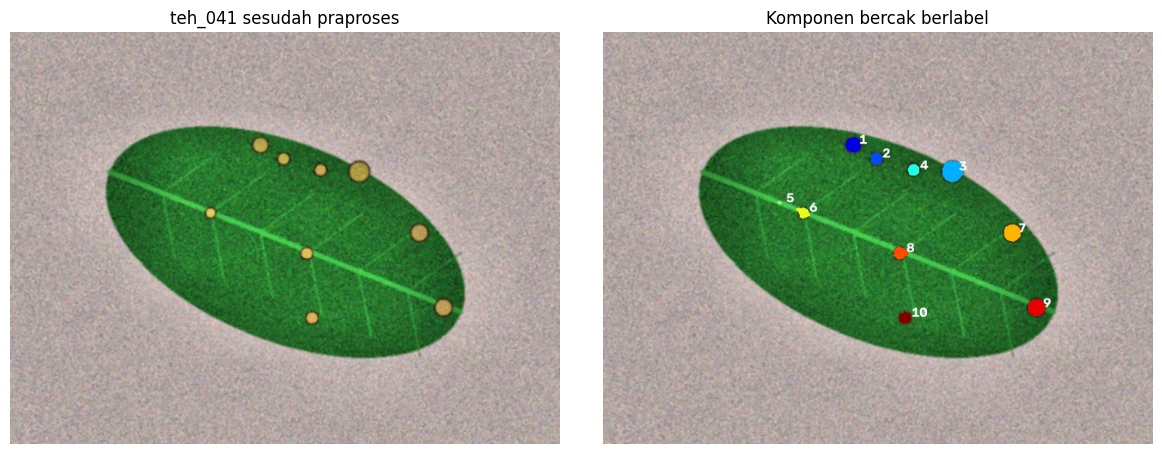

In [15]:

# LANGKAH 4.2 - KOMPONEN TERHUBUNG DAN PENGUKURAN BERCAK

MM_PER_PX = 0.4375

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats(
        (m > 0).astype(np.uint8),
        connectivity=konek
    )

    baris = []

    for i in range(1, n):
        kontur, _ = cv2.findContours(
            (lbl == i).astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_NONE
        )

        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)

        kebulatan = (
            0.0 if keliling == 0
            else 4 * np.pi * A / keliling**2
        )

        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)

        baris.append([
            i,
            A,
            round(A * MM_PER_PX**2, 2),
            round(keliling, 1),
            round(kebulatan, 2),
            round(rasio, 2),
            int(cen[i][0]),
            int(cen[i][1])
        ])

    kolom = [
        "label", "luas_px", "luas_mm2", "keliling_px",
        "kebulatan", "rasio_aspek", "cx", "cy"
    ]

    return pd.DataFrame(baris, columns=kolom), lbl


# Muat citra teh_041
img, md, mb = muat("teh_041.png")

# Praproses dan membuat mask bercak
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)

bersih = cv2.morphologyEx(
    cv2.morphologyEx(
        bercak_awal(pra_, m_daun),
        cv2.MORPH_OPEN,
        SE(5)
    ),
    cv2.MORPH_CLOSE,
    SE(5)
)

# Bandingkan jumlah komponen konektivitas 4 dan 8
for konek in [4, 8]:
    print(
        f"Konektivitas {konek}: "
        f"{jumlah_komponen(bersih, konek)} komponen"
    )

# Ukur setiap komponen menggunakan konektivitas 8
tabel_kom, lbl = ukur_komponen(bersih, konek=8)

print("\nTABEL PENGUKURAN BERCAK TEH_041")
display(tabel_kom.round(2))

# Visualisasi komponen dengan label angka
skala = (lbl * (255 / max(lbl.max(), 1))).astype(np.uint8)
warna = cv2.applyColorMap(skala, cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]

for _, r in tabel_kom.iterrows():
    cv2.putText(
        warna,
        str(int(r.label)),
        (int(r.cx) + 8, int(r.cy)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        2
    )

tampil(
    [pra_, warna],
    ["teh_041 sesudah praproses", "Komponen bercak berlabel"],
    ukuran=(12, 4.5)
)

# Simpan tabel hasil pengukuran
tabel_kom.to_csv(
    os.path.join(BASE, "hasil", "p6_ukuran_teh041.csv"),
    index=False
)

print("\nTabel tersimpan: hasil/p6_ukuran_teh041.csv")


In [16]:

# LANGKAH 4.3 - PENYARINGAN BERCAK PALSU

def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)

    lolos = tabel_k[
        (tabel_k.luas_px >= luas_min) &
        (tabel_k.kebulatan >= bulat_min) &
        (tabel_k.rasio_aspek <= rasio_maks)
    ]

    hasil = (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8)

    return hasil, lolos


# Empat aturan penyaringan yang diuji
aturan = {
    "tanpa saring": (0, 0, 99),
    "luas >= 20": (20, 0, 99),
    "luas + kebulatan": (20, 0.5, 99),
    "luas + kebulatan + rasio": (20, 0.5, 1.8)
}

baris = []

# Pengujian pada seluruh 60 citra
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE(5)
        ),
        cv2.MORPH_CLOSE,
        SE(5)
    )

    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)

        baris.append([
            d.kelas,
            nm,
            jumlah_komponen(f),
            jumlah_komponen(mb)
        ])

# Membuat tabel hasil pengujian
uji = pd.DataFrame(
    baris,
    columns=["kelas", "aturan", "jumlah", "acuan"]
)

uji["galat"] = (uji.jumlah - uji.acuan).abs()

print("GALAT JUMLAH KOMPONEN BERDASARKAN ATURAN")
display(
    uji.pivot_table(
        index="aturan",
        columns="kelas",
        values="galat"
    ).round(2)
)

print("\nJUMLAH DAUN SEHAT YANG MASIH MEMILIKI BERCAK PALSU")

palsu = (
    uji[uji.kelas == "sehat"]
    .assign(palsu=lambda t: t.jumlah > 0)
    .groupby("aturan").palsu.sum()
)

display(palsu.to_frame("jumlah_daun_sehat_bercak_palsu"))

# Simpan hasil pengujian
uji.to_csv(
    os.path.join(BASE, "hasil", "p6_penyaringan_bercak.csv"),
    index=False
)

print("\nHasil tersimpan di hasil/p6_penyaringan_bercak.csv")


GALAT JUMLAH KOMPONEN BERDASARKAN ATURAN


kelas,berat,ringan,sehat
aturan,,,
luas + kebulatan,1.25,1.45,1.30
luas + kebulatan + rasio,1.10,0.80,0.75
luas >= 20,1.35,2.40,1.75
tanpa saring,1.70,3.45,3.10



JUMLAH DAUN SEHAT YANG MASIH MEMILIKI BERCAK PALSU


,jumlah_daun_sehat_bercak_palsu
aturan,
luas + kebulatan,10
luas + kebulatan + rasio,7
luas >= 20,10
tanpa saring,11



Hasil tersimpan di hasil/p6_penyaringan_bercak.csv


JUMLAH KOMPONEN BERDASARKAN STATUS


,jumlah
status,
benar,195
palsu,146



JUMLAH KOMPONEN BERDASARKAN KELAS DAN STATUS


status,benar,palsu
kelas,,
berat,159,21
ringan,36,63
sehat,0,62


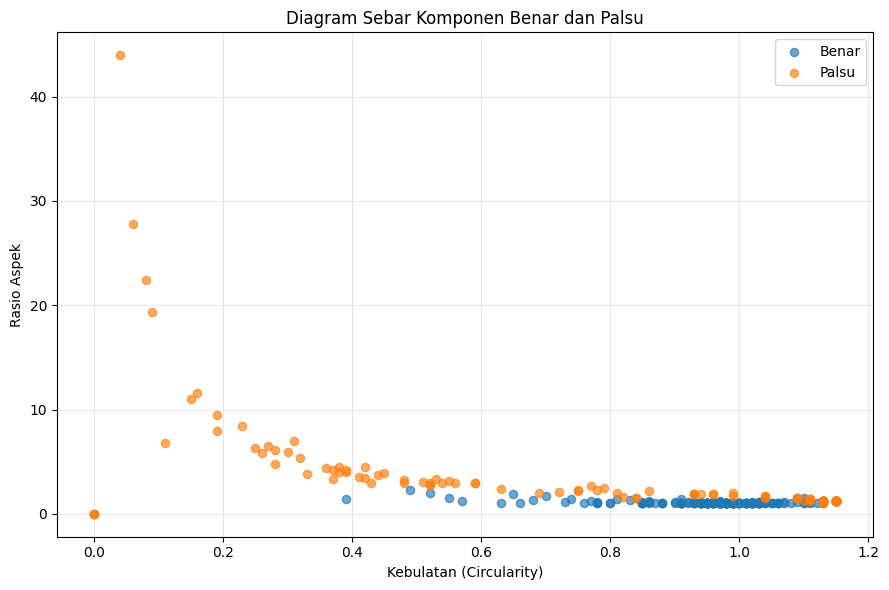

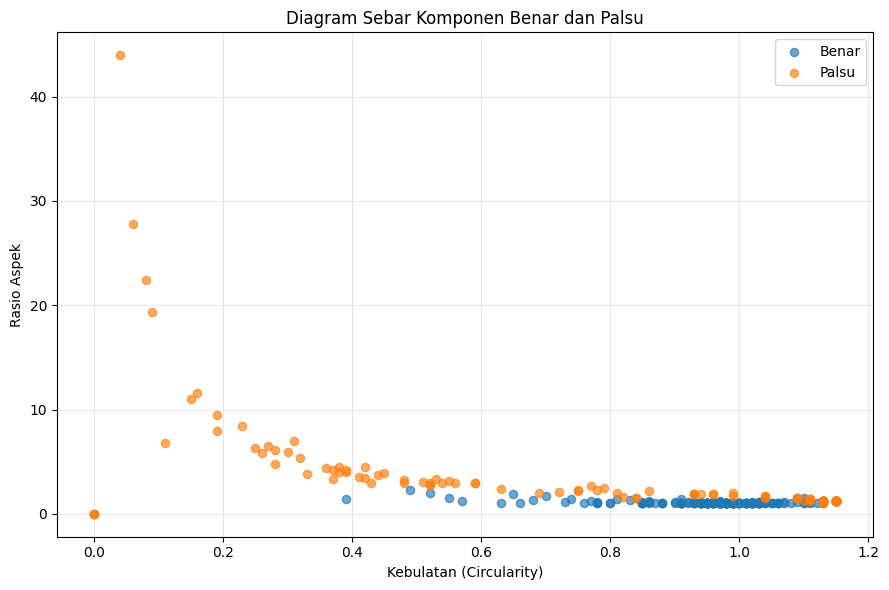


File tersimpan:
- hasil/p6_analisis_ambang.csv
- hasil/p6_scatter_ambang.png


In [17]:

# LANGKAH 4.4 - DASAR AMBANG PENYARINGAN

data_komponen = []

# Periksa seluruh 60 citra
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)

    # Pembersihan mask bercak: opening kemudian closing
    bersih = cv2.morphologyEx(
        cv2.morphologyEx(
            bercak_awal(pra_, m_daun),
            cv2.MORPH_OPEN,
            SE(5)
        ),
        cv2.MORPH_CLOSE,
        SE(5)
    )

    # Label dan ukur setiap komponen
    tabel_k, lbl = ukur_komponen(bersih, konek=8)

    # Tentukan komponen benar atau palsu
    for _, r in tabel_k.iterrows():
        nomor = int(r.label)

        mask_komponen = (lbl == nomor)
        luas_komponen = int(mask_komponen.sum())

        # Hitung piksel komponen yang masuk mask bercak acuan
        tumpang_tindih = np.count_nonzero(
            mask_komponen & (mb > 0)
        )

        proporsi = tumpang_tindih / luas_komponen

        status = "benar" if proporsi > 0.5 else "palsu"

        data_komponen.append([
            d.nama_file,
            d.kelas,
            nomor,
            int(r.luas_px),
            r.kebulatan,
            r.rasio_aspek,
            round(proporsi, 3),
            status
        ])

# Buat DataFrame seluruh komponen
data_44 = pd.DataFrame(
    data_komponen,
    columns=[
        "nama_file", "kelas", "label", "luas_px",
        "kebulatan", "rasio_aspek",
        "proporsi_acuan", "status"
    ]
)

print("JUMLAH KOMPONEN BERDASARKAN STATUS")
display(data_44["status"].value_counts().to_frame("jumlah"))

print("\nJUMLAH KOMPONEN BERDASARKAN KELAS DAN STATUS")
display(
    pd.crosstab(data_44["kelas"], data_44["status"])
)

# Diagram sebar kebulatan terhadap rasio aspek
plt.figure(figsize=(9, 6))

for status in ["benar", "palsu"]:
    subset = data_44[data_44["status"] == status]

    plt.scatter(
        subset["kebulatan"],
        subset["rasio_aspek"],
        label=status.capitalize(),
        alpha=0.65,
        s=35
    )

plt.xlabel("Kebulatan (Circularity)")
plt.ylabel("Rasio Aspek")
plt.title("Diagram Sebar Komponen Benar dan Palsu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Simpan data dan diagram
data_44.to_csv(
    os.path.join(BASE, "hasil", "p6_analisis_ambang.csv"),
    index=False
)

plt.figure(figsize=(9, 6))

for status in ["benar", "palsu"]:
    subset = data_44[data_44["status"] == status]

    plt.scatter(
        subset["kebulatan"],
        subset["rasio_aspek"],
        label=status.capitalize(),
        alpha=0.65,
        s=35
    )

plt.xlabel("Kebulatan (Circularity)")
plt.ylabel("Rasio Aspek")
plt.title("Diagram Sebar Komponen Benar dan Palsu")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(BASE, "hasil", "p6_scatter_ambang.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFile tersimpan:")
print("- hasil/p6_analisis_ambang.csv")
print("- hasil/p6_scatter_ambang.png")


In [18]:
# Memuat citra dan mask acuan
img, md, mb = muat("teh_041.png")

# Membuat mask bercak hasil segmentasi
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)

bersih = cv2.morphologyEx(
    cv2.morphologyEx(
        bercak_awal(pra_, m_daun),
        cv2.MORPH_OPEN,
        SE(5)
    ),
    cv2.MORPH_CLOSE,
    SE(5)
)

# Penyaringan menggunakan aturan terbaik dari langkah 4.3
hasil_saring, tabel_lolos = saring(
    bersih,
    luas_min=20,
    bulat_min=0.5,
    rasio_maks=1.8
)

# Menghitung luas hasil segmentasi dan mask acuan
MM_PER_PX = 0.4375
luas_acuan_px = np.count_nonzero(mb > 0)
luas_acuan_mm = luas_acuan_px * (MM_PER_PX ** 2)

luas_bersih_px = np.count_nonzero(bersih > 0)
luas_bersih_mm = luas_bersih_px * (MM_PER_PX ** 2)

luas_saring_px = np.count_nonzero(hasil_saring > 0)
luas_saring_mm = luas_saring_px * (MM_PER_PX ** 2)

# Menghitung persentase selisih
selisih_bersih = (
    (luas_bersih_mm - luas_acuan_mm) / luas_acuan_mm
) * 100

selisih_saring = (
    (luas_saring_mm - luas_acuan_mm) / luas_acuan_mm
) * 100

print("PERBANDINGAN LUAS BERCAK TEH_041")
print(f"Luas mask acuan       : {luas_acuan_px} px = {luas_acuan_mm:.2f} mm²")
print(f"Luas hasil morfologi  : {luas_bersih_px} px = {luas_bersih_mm:.2f} mm²")
print(f"Luas setelah saring   : {luas_saring_px} px = {luas_saring_mm:.2f} mm²")
print(f"Selisih morfologi     : {selisih_bersih:.2f}%")
print(f"Selisih setelah saring: {selisih_saring:.2f}%")

PERBANDINGAN LUAS BERCAK TEH_041
Luas mask acuan       : 2354 px = 450.57 mm²
Luas hasil morfologi  : 2117 px = 405.21 mm²
Luas setelah saring   : 2100 px = 401.95 mm²
Selisih morfologi     : -10.07%
Selisih setelah saring: -10.79%


In [21]:

%%writefile /content/drive/MyDrive/simuteh-2330511091/src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""

import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,
    "k": 4.0,
    "se_bentuk": "elips",
    "se_open": 5,
    "se_close": 5,
    "luas_min": 20,
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,
    "batas_berat": 2.0,
    "mm_per_px": 0.4375,
}

_BENTUK = {
    "elips": cv2.MORPH_ELLIPSE,
    "persegi": cv2.MORPH_RECT,
    "silang": cv2.MORPH_CROSS
}


def _se(p, uk):
    return cv2.getStructuringElement(
        _BENTUK[p["se_bentuk"]], (uk, uk)
    )


def bersihkan(biner, p):
    """Opening membuang derau dan closing menutup celah."""
    hasil = biner.copy()

    # TODO 1: Opening
    if p["se_open"] > 0:
        hasil = cv2.morphologyEx(
            hasil, cv2.MORPH_OPEN, _se(p, p["se_open"])
        )

    # TODO 2: Closing
    if p["se_close"] > 0:
        hasil = cv2.morphologyEx(
            hasil, cv2.MORPH_CLOSE, _se(p, p["se_close"])
        )

    return hasil


def ukur_dan_saring(biner, p):
    """Mengukur dan menyaring setiap komponen bercak."""

    # TODO 3: Label komponen dengan konektivitas 8
    jumlah, label, stats, pusat = cv2.connectedComponentsWithStats(
        (biner > 0).astype(np.uint8),
        connectivity=8
    )

    keluar = np.zeros_like(biner)
    daftar = []

    for i in range(1, jumlah):
        mask = (label == i).astype(np.uint8)

        # Kontur komponen
        kontur, _ = cv2.findContours(
            mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE
        )

        if not kontur:
            continue

        kontur = kontur[0]

        # TODO 4: Menghitung karakteristik komponen
        luas = int(stats[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur, True)

        kebulatan = (
            0.0 if keliling == 0
            else 4 * np.pi * luas / (keliling ** 2)
        )

        w, h = cv2.minAreaRect(kontur)[1]
        rasio = max(w, h) / max(min(w, h), 1)

        # TODO 5: Penyaringan komponen
        if (
            luas >= p["luas_min"]
            and kebulatan >= p["bulat_min"]
            and rasio <= p["rasio_maks"]
        ):
            keluar[mask > 0] = 255

            daftar.append({
                "label": int(i),
                "luas_px": luas,
                "luas_mm2": round(
                    luas * p["mm_per_px"] ** 2, 2
                ),
                "keliling_px": round(float(keliling), 2),
                "kebulatan": round(float(kebulatan), 3),
                "rasio_aspek": round(float(rasio), 3),
                "cx": int(pusat[i][0]),
                "cy": int(pusat[i][1])
            })

    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Menganalisis bercak pada citra BGR hasil praproses."""

    p = {**PARAM_BERCAK, **(p or {})}

    m_daun = mask_daun_awal(img_praproses)

    biner = bercak_awal(
        img_praproses,
        m_daun,
        kanal=p["kanal"],
        k=p["k"]
    )

    m_bercak, daftar = ukur_dan_saring(
        bersihkan(biner, p), p
    )

    # TODO 6: Menghitung persentase luas bercak
    luas_daun = np.count_nonzero(m_daun > 0)
    luas_bercak = np.count_nonzero(m_bercak > 0)

    persen = (
        0.0 if luas_daun == 0
        else luas_bercak / luas_daun * 100
    )

    # TODO 7: Menentukan kelas mutu
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"

    return {
        "mask_daun": m_daun,
        "mask_bercak": m_bercak,
        "jumlah_bercak": len(daftar),
        "persen_bercak": round(float(persen), 3),
        "kelas": kelas,
        "bercak": daftar
    }


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)


Overwriting /content/drive/MyDrive/simuteh-2330511091/src/bercak.py


HASIL UJI MODUL BERCAK
Jumlah bercak : 9
Persen bercak : 2.652 %
Kelas mutu    : Bercak Berat
Jumlah data ukuran: 9


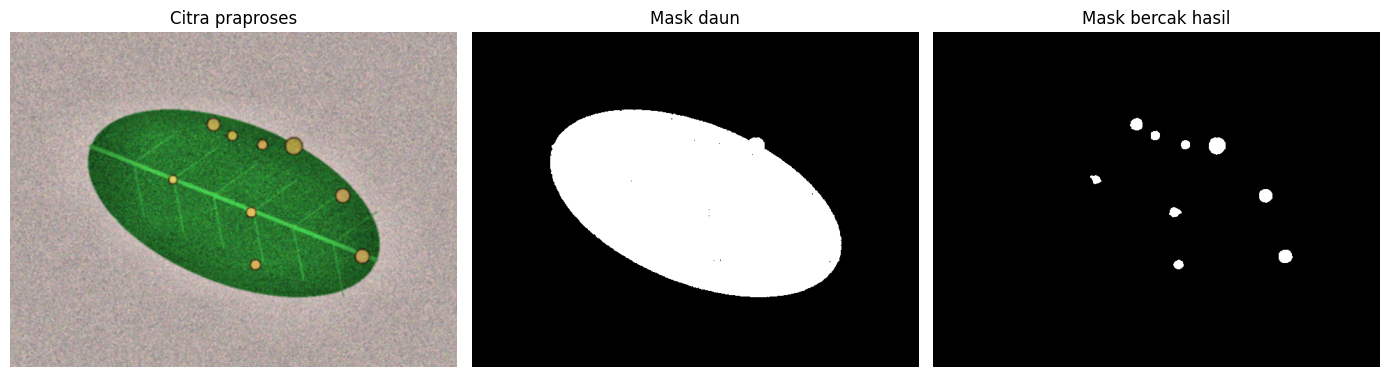

In [22]:

import importlib
import bercak

importlib.reload(bercak)

# Uji satu citra teh_041
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)

hasil = bercak.analisis_daun(pra_)

print("HASIL UJI MODUL BERCAK")
print("Jumlah bercak :", hasil["jumlah_bercak"])
print("Persen bercak :", hasil["persen_bercak"], "%")
print("Kelas mutu    :", hasil["kelas"])
print("Jumlah data ukuran:", len(hasil["bercak"]))

# Tampilkan citra dan mask hasil
tampil(
    [pra_, hasil["mask_daun"], hasil["mask_bercak"]],
    ["Citra praproses", "Mask daun", "Mask bercak hasil"]
)


EVALUASI MODUL BERCAK
Galat absolut rerata persen bercak : 0.622
Korelasi persen prediksi vs acuan  : 0.909
Akurasi kelas                     : 0.85

CONFUSION MATRIX
Prediksi       Bercak Berat  Bercak Ringan  Sehat
Acuan                                            
Bercak Berat             18              1      1
Bercak Ringan             0             15      5
Sehat                     0              2     18

AKURASI BERDASARKAN KONDISI CAHAYA
kondisi
bayangan          0.92
gelap             0.92
kontras_rendah    0.67
normal            0.75
terang            1.00
Name: benar, dtype: float64


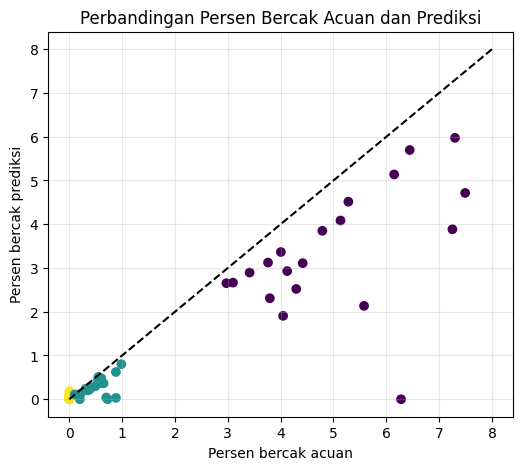

In [23]:

import importlib
import bercak
importlib.reload(bercak)

# Parameter kosong berarti menggunakan parameter bawaan
PB = {}

# Simpan parameter yang digunakan
bercak.simpan_param(
    PB,
    os.path.join(BASE, "hasil", "param_bercak.json")
)

baris = []

for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)

    h = bercak.analisis_daun(
        praproses(img, PARAM),
        PB
    )

    baris.append([
        d.nama_file,
        d.kelas,
        d.kondisi_cahaya,
        np.count_nonzero(mb > 0) /
        max(np.count_nonzero(md > 0), 1) * 100,
        h["persen_bercak"],
        jumlah_komponen(mb),
        h["jumlah_bercak"],
        h["kelas"]
    ])

ev = pd.DataFrame(
    baris,
    columns=[
        "nama", "kelas", "kondisi",
        "persen_acuan", "persen_prediksi",
        "jumlah_acuan", "jumlah_prediksi",
        "kelas_prediksi"
    ]
)

ev["kelas_acuan"] = ev["kelas"].map({
    "sehat": "Sehat",
    "ringan": "Bercak Ringan",
    "berat": "Bercak Berat"
})

# Simpan hasil evaluasi
ev.to_csv(
    os.path.join(BASE, "hasil", "p6_evaluasi_bercak.csv"),
    index=False
)

# Menghitung metrik evaluasi
galat = (
    ev["persen_prediksi"] - ev["persen_acuan"]
).abs().mean()

korelasi = ev[
    ["persen_prediksi", "persen_acuan"]
].corr().iloc[0, 1]

akurasi = (
    ev["kelas_prediksi"] == ev["kelas_acuan"]
).mean()

print("EVALUASI MODUL BERCAK")
print("Galat absolut rerata persen bercak :", round(galat, 3))
print("Korelasi persen prediksi vs acuan  :", round(korelasi, 3))
print("Akurasi kelas                     :", round(akurasi, 3))

print("\nCONFUSION MATRIX")
print(pd.crosstab(
    ev["kelas_acuan"],
    ev["kelas_prediksi"],
    rownames=["Acuan"],
    colnames=["Prediksi"]
))

print("\nAKURASI BERDASARKAN KONDISI CAHAYA")
print(
    ev.assign(
        benar=ev["kelas_prediksi"] == ev["kelas_acuan"]
    ).groupby("kondisi")["benar"].mean().round(2)
)

# Diagram sebar persen bercak
plt.figure(figsize=(6, 5))
plt.scatter(
    ev["persen_acuan"],
    ev["persen_prediksi"],
    c=ev["kelas"].astype("category").cat.codes
)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("Persen bercak acuan")
plt.ylabel("Persen bercak prediksi")
plt.title("Perbandingan Persen Bercak Acuan dan Prediksi")
plt.grid(alpha=0.3)
plt.show()


JUMLAH CITRA SALAH: 9

DAFTAR CITRA SALAH:
       nama   kelas_acuan kelas_prediksi        kondisi
teh_011.png         Sehat  Bercak Ringan         normal
teh_012.png         Sehat  Bercak Ringan          gelap
teh_021.png Bercak Ringan          Sehat         normal
teh_029.png Bercak Ringan          Sehat kontras_rendah
teh_034.png Bercak Ringan          Sehat kontras_rendah
teh_036.png Bercak Ringan          Sehat         normal
teh_039.png Bercak Ringan          Sehat kontras_rendah
teh_054.png  Bercak Berat          Sehat kontras_rendah
teh_060.png  Bercak Berat  Bercak Ringan       bayangan


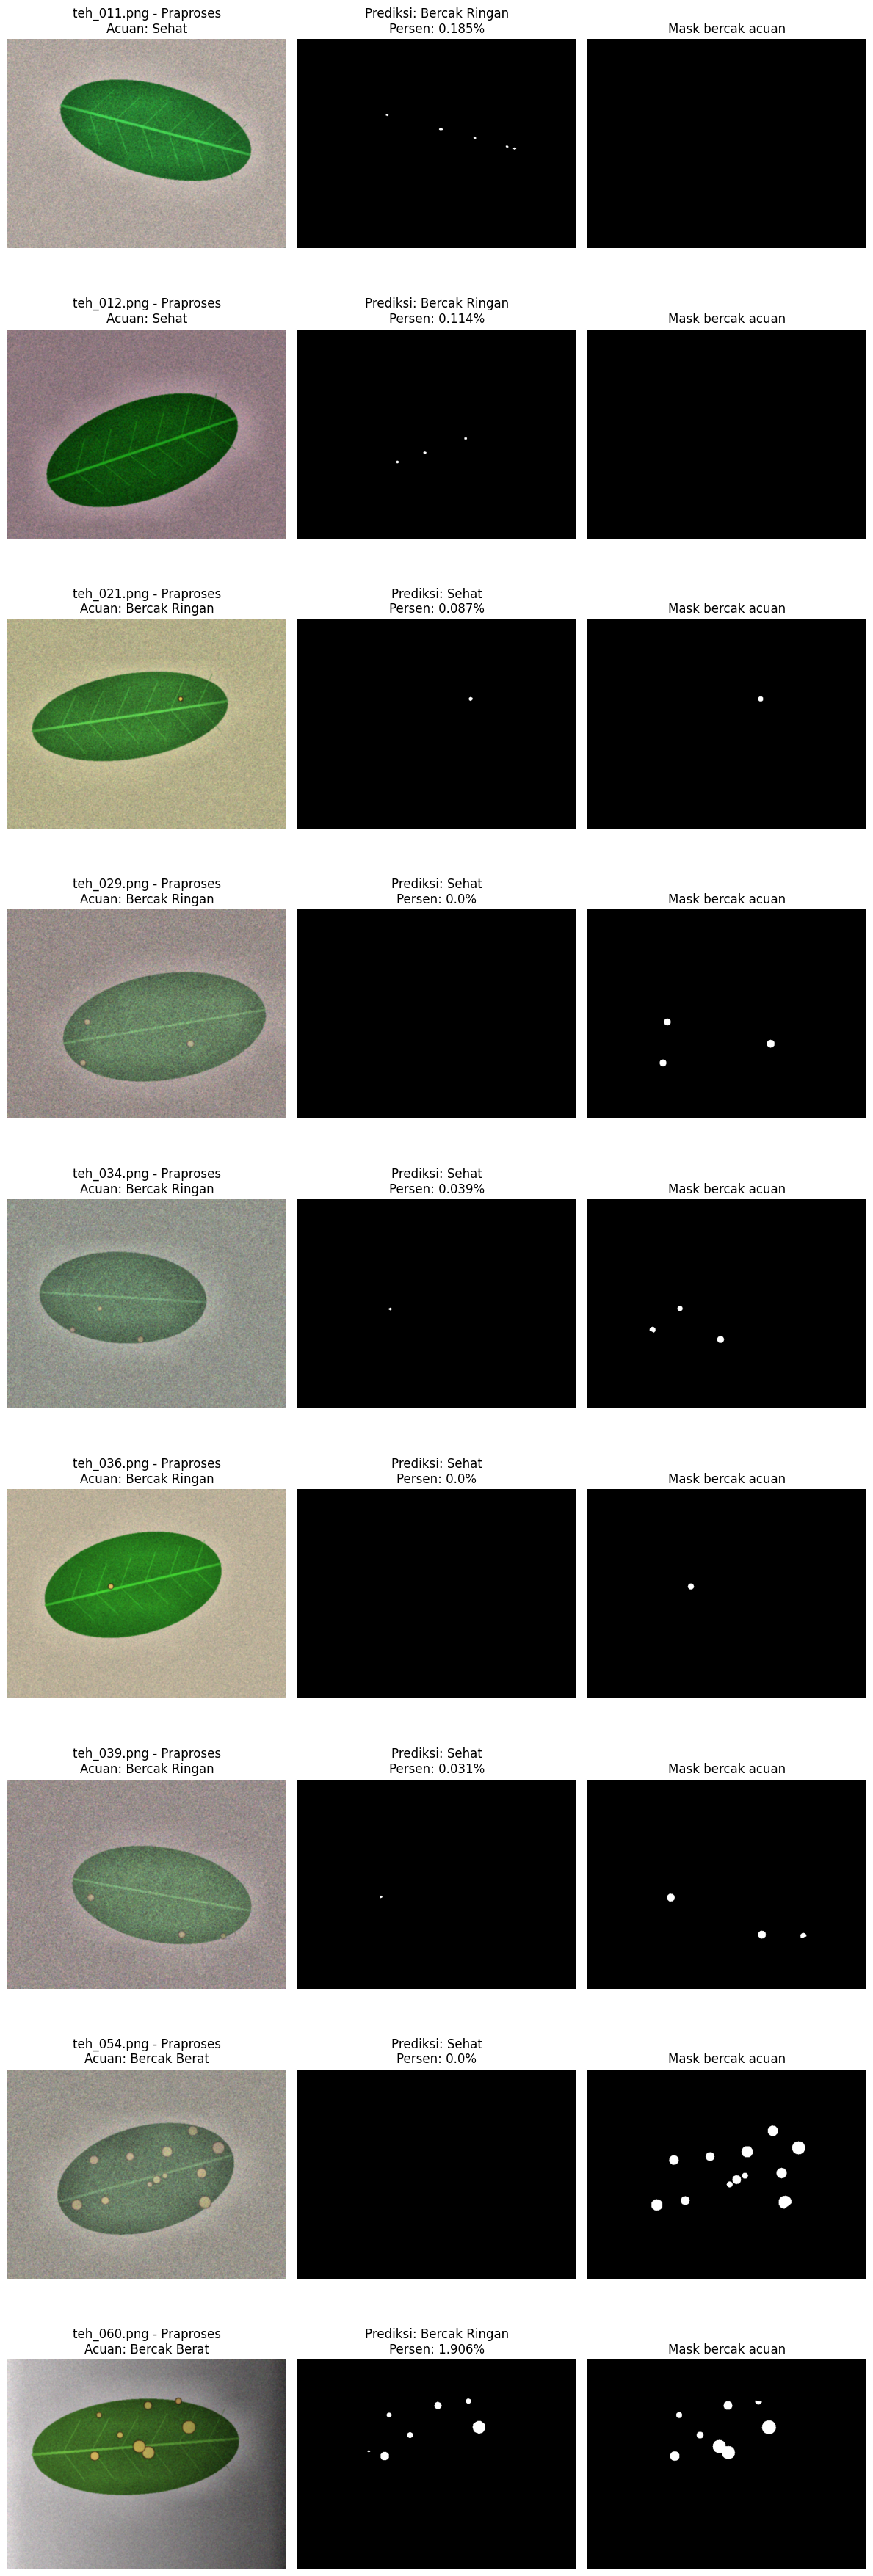

Panel kesalahan disimpan: /content/drive/MyDrive/simuteh-2330511091/hasil/p6_kesalahan_klasifikasi.png


In [24]:

# Mengambil citra yang salah diklasifikasikan
salah = ev[ev["kelas_prediksi"] != ev["kelas_acuan"]].copy()

print("JUMLAH CITRA SALAH:", len(salah))
print("\nDAFTAR CITRA SALAH:")
print(
    salah[
        ["nama", "kelas_acuan", "kelas_prediksi", "kondisi"]
    ].to_string(index=False)
)

# Menampilkan perbandingan setiap citra yang salah
fig, axes = plt.subplots(
    len(salah), 3,
    figsize=(12, 4 * len(salah))
)

if len(salah) == 1:
    axes = np.array([axes])

for i, (_, d) in enumerate(salah.iterrows()):
    img, md, mb = muat(d["nama"])
    pra_ = praproses(img, PARAM)

    h = bercak.analisis_daun(pra_, PB)

    axes[i, 0].imshow(cv2.cvtColor(pra_, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(
        f'{d["nama"]} - Praproses\nAcuan: {d["kelas_acuan"]}'
    )

    axes[i, 1].imshow(h["mask_bercak"], cmap="gray")
    axes[i, 1].set_title(
        f'Prediksi: {d["kelas_prediksi"]}\n'
        f'Persen: {h["persen_bercak"]}%'
    )

    axes[i, 2].imshow(mb, cmap="gray")
    axes[i, 2].set_title("Mask bercak acuan")

    for j in range(3):
        axes[i, j].axis("off")

plt.tight_layout()

# Menyimpan panel kesalahan
path = os.path.join(
    BASE, "hasil", "p6_kesalahan_klasifikasi.png"
)
plt.savefig(path, dpi=200, bbox_inches="tight")
plt.show()

print("Panel kesalahan disimpan:", path)
